In [1]:
import pandas as pd
print("DriftLens data exploration started!")


DriftLens data exploration started!


In [3]:
from pathlib import Path
import pandas as pd

ROOT = Path.cwd()
csv_path = ROOT / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (7043, 21)
Number of rows: 7043
Number of columns: 21


In [4]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [6]:
df.isnull().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [7]:
pd.to_numeric(df["TotalCharges"], errors="coerce").isna().sum()

np.int64(11)

In [8]:
df["Churn"].value_counts()

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [9]:
df["Churn"].value_counts(normalize=True).mul(100).round(2)

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

Matplotlib is building the font cache; this may take a moment.


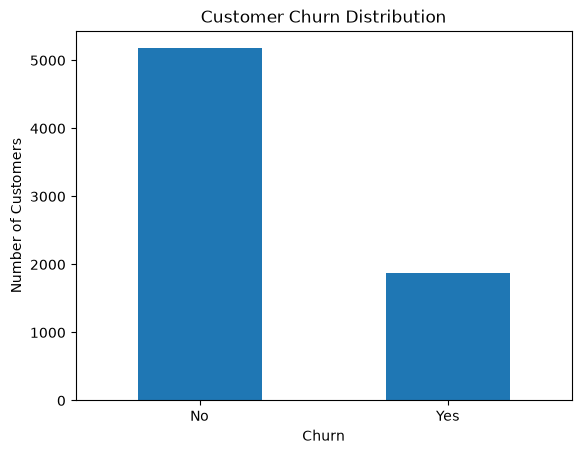

In [10]:
import matplotlib.pyplot as plt

churn_counts = df["Churn"].value_counts()

churn_counts.plot(kind="bar")
plt.title("Customer Churn Distribution")
plt.xlabel("Churn")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.show()

In [11]:
import pandas as pd

reference = pd.read_csv("data/reference.csv")
incoming = pd.read_csv("data/incoming.csv")

print("Reference shape:", reference.shape)
print("Incoming shape:", incoming.shape)

print("\nReference contract distribution:")
print(reference["Contract"].value_counts(normalize=True).mul(100).round(2))

print("\nIncoming contract distribution:")
print(incoming["Contract"].value_counts(normalize=True).mul(100).round(2))

Reference shape: (1409, 21)
Incoming shape: (1409, 21)

Reference contract distribution:
Contract
Month-to-month    55.71
Two year          23.49
One year          20.79
Name: proportion, dtype: float64

Incoming contract distribution:
Contract
Month-to-month    55.78
Two year          24.06
One year          20.16
Name: proportion, dtype: float64


In [12]:
# Make a copy so the original incoming data stays unchanged
drifted = incoming.copy()

print("Before drift:")
print(
    drifted["Contract"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Before drift:
Contract
Month-to-month    55.78
Two year          24.06
One year          20.16
Name: proportion, dtype: float64


In [13]:
# Simulate a sudden increase in month-to-month contracts
drifted["Contract"] = "Month-to-month"

print("After drift:")
print(
    drifted["Contract"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

After drift:
Contract
Month-to-month    100.0
Name: proportion, dtype: float64


In [14]:
from scipy.stats import chi2_contingency
import pandas as pd

feature = "Contract"

comparison = pd.DataFrame({
    "Reference": reference[feature].value_counts(),
    "Incoming": drifted[feature].value_counts()
}).fillna(0)

chi2, p_value, dof, expected = chi2_contingency(comparison)

print("Feature:", feature)
print("Chi-square statistic:", round(chi2, 3))
print("P-value:", p_value)

if p_value < 0.05:
    print("ALERT: Significant feature drift detected!")
else:
    print("No statistically significant drift detected.")

Feature: Contract
Chi-square statistic: 801.473
P-value: 9.169080743092739e-175
ALERT: Significant feature drift detected!


In [16]:
import pandas as pd
from scipy.stats import chi2_contingency

def detect_categorical_drift(reference, incoming, feature, threshold=0.05):

    # Count each category in both datasets
    comparison = pd.DataFrame({
        "Reference": reference[feature].value_counts(),
        "Incoming": incoming[feature].value_counts()
    }).fillna(0)

    # Perform the Chi-square test
    chi2, p_value, dof, expected = chi2_contingency(comparison)

    return {
        "Feature": feature,
        "Chi-square": round(chi2, 3),
        "P-value": p_value,
        "Drift detected": p_value < threshold
    }

In [17]:
features = ["Contract", "InternetService", "PaymentMethod"]

results = pd.DataFrame([
    detect_categorical_drift(reference, drifted, feature)
    for feature in features
])

display(results)

,Feature,Chi-square,P-value,Drift detected
0,Contract,801.473,9.169081e-175,True
1,InternetService,0.713,7.000111e-01,False
2,PaymentMethod,3.161,3.674357e-01,False


In [18]:
categorical_features = reference.select_dtypes(
    include=["object", "category"]
).columns.tolist()

# Exclude target and prediction columns
categorical_features = [
    col for col in categorical_features
    if col not in ["target", "prediction"]
]

print("Categorical features:")
print(categorical_features)
print("Total features:", len(categorical_features))

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Total features: 15


C:\Users\KIIT\AppData\Local\Temp\ipykernel_860\1752741724.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features = reference.select_dtypes(


In [19]:
results = pd.DataFrame([
    detect_categorical_drift(reference, drifted, feature)
    for feature in categorical_features
])

results = results.sort_values(
    by="P-value",
    ascending=True
).reset_index(drop=True)

display(results)

,Feature,Chi-square,P-value,Drift detected
0,Contract,801.473,9.169081e-175,True
1,gender,2.159,1.416947e-01,False
2,PaperlessBilling,1.081,2.985006e-01,False
3,PaymentMethod,3.161,3.674357e-01,False
4,Dependents,0.487,4.853360e-01,False
5,TechSupport,0.889,6.411113e-01,False
6,DeviceProtection,0.728,6.947632e-01,False
7,InternetService,0.713,7.000111e-01,False
8,Partner,0.142,7.062309e-01,False
9,StreamingTV,0.639,7.265821e-01,False


In [20]:
drift_count = results["Drift detected"].sum()
total_features = len(results)

print("Total categorical features:", total_features)
print("Features with drift:", drift_count)
print("Features without detected drift:", total_features - drift_count)

Total categorical features: 15
Features with drift: 1
Features without detected drift: 14


In [22]:
test_incoming = incoming.copy()

test_incoming["Contract"] = "Month-to-month"

print("Test data created!")

Test data created!


In [23]:
from pathlib import Path

test_path = Path("data/test_incoming.csv")
test_incoming.to_csv(test_path, index=False)

print("Test data saved successfully!")

Test data saved successfully!


In [25]:
import sqlite3
import pandas as pd
from pathlib import Path

db_path = Path("data/driftlens.db")

connection = sqlite3.connect(db_path)

saved_results = pd.read_sql_query(
    "SELECT * FROM drift_results",
    connection
)

connection.close()

display(saved_results)

,Feature,Chi-square,P-value,Drift detected,run_time
0,gender,2.159,1.416947e-01,0,2026-10-17T20:29:18
1,Partner,0.142,7.062309e-01,0,2026-10-17T20:29:18
2,Dependents,0.487,4.853360e-01,0,2026-10-17T20:29:18
3,PhoneService,0.004,9.487994e-01,0,2026-10-17T20:29:18
4,MultipleLines,0.368,8.319899e-01,0,2026-10-17T20:29:18
5,InternetService,0.713,7.000111e-01,0,2026-10-17T20:29:18
6,OnlineSecurity,0.629,7.301253e-01,0,2026-10-17T20:29:18
7,OnlineBackup,0.588,7.451485e-01,0,2026-10-17T20:29:18
8,DeviceProtection,0.728,6.947632e-01,0,2026-10-17T20:29:18
9,TechSupport,0.889,6.411113e-01,0,2026-10-17T20:29:18
